# SPIRES fSCA and categorical snow change
Crop SPIRES fSCA to the NISAR AOI, classify snow cover, and compute categorical snow change for each NISAR pair.

In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from pathlib import Path
from seaborn import set_theme
set_theme()

import sys
import os

# import from this repo
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2
from scripts.fsca import build_fsca_cube, classify_fsca, classify_change, change_labels

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


First, we setup logging to get useful information and error messages.

In [3]:
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s', force=True)

Load the NISAR cube and list the SPIRES files (the MODIS tile covering the AOI).

In [4]:
data_dir = "../data/"
track = 19
frame = 21
tile = "h09v05"
nisar_80m = xr.open_zarr(data_dir + f'nisar/zarrs/track{str(track).zfill(3)}_frame{str(frame).zfill(3)}/snow_80m.zarr')
starts = nisar_80m['start'].values
ends = nisar_80m['end'].values
fsca_files = sorted(Path(data_dir + f'fsca_spires/{tile}').glob('SPIRES_HIST_*.nc'))
len(fsca_files)

365

Build the fSCA cube over the NISAR bounding box, in the NISAR UTM zone. Pass a different `(xmin, ymin, xmax, ymax)` in that CRS to use another AOI.

In [5]:
aoi = nisar_80m.rio.bounds()
fsca = build_fsca_cube(fsca_files, aoi, nisar_80m.rio.crs)
fsca

/Users/JULIALOBER/miniforge3/envs/coherence/lib/python3.11/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.82.1. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(
2026-10-14 13:55:23,261 - INFO - fsca cube: {'time': 365, 'y': 61, 'x': 47} from 2025-10-01T00:00:00.000000000 to 2026-09-30T00:00:00.000000000


<xarray.DataArray 'fsca' (time: 365, y: 61, x: 47)> Size: 4MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
...
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]],
      shape=(365, 61, 47), dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 3kB 2025-10-01 2025-10-02 ... 2026-09-30
  * y            (y) float64 488B 4.323e+06 4.322e+06 ... 4.281e+06 4.281e+06
  * x            (x) float64 376B 3.162e+05 3.169e+05 ... 3.477e+05 3.484e+05
    spatial_ref  int64 8B 0
Attributes:
    long_name:  fractional snow covered area
    units:      %

Reproject to NISAR grid and mask for valid pixels 

In [13]:
from rasterio.enums import Resampling

fsca = fsca.rio.reproject_match(nisar_80m, resampling=Resampling.bilinear)
fsca = fsca.where(~nisar_80m['elevation'].isnull())

Plot fSCA on each pair start and end date.

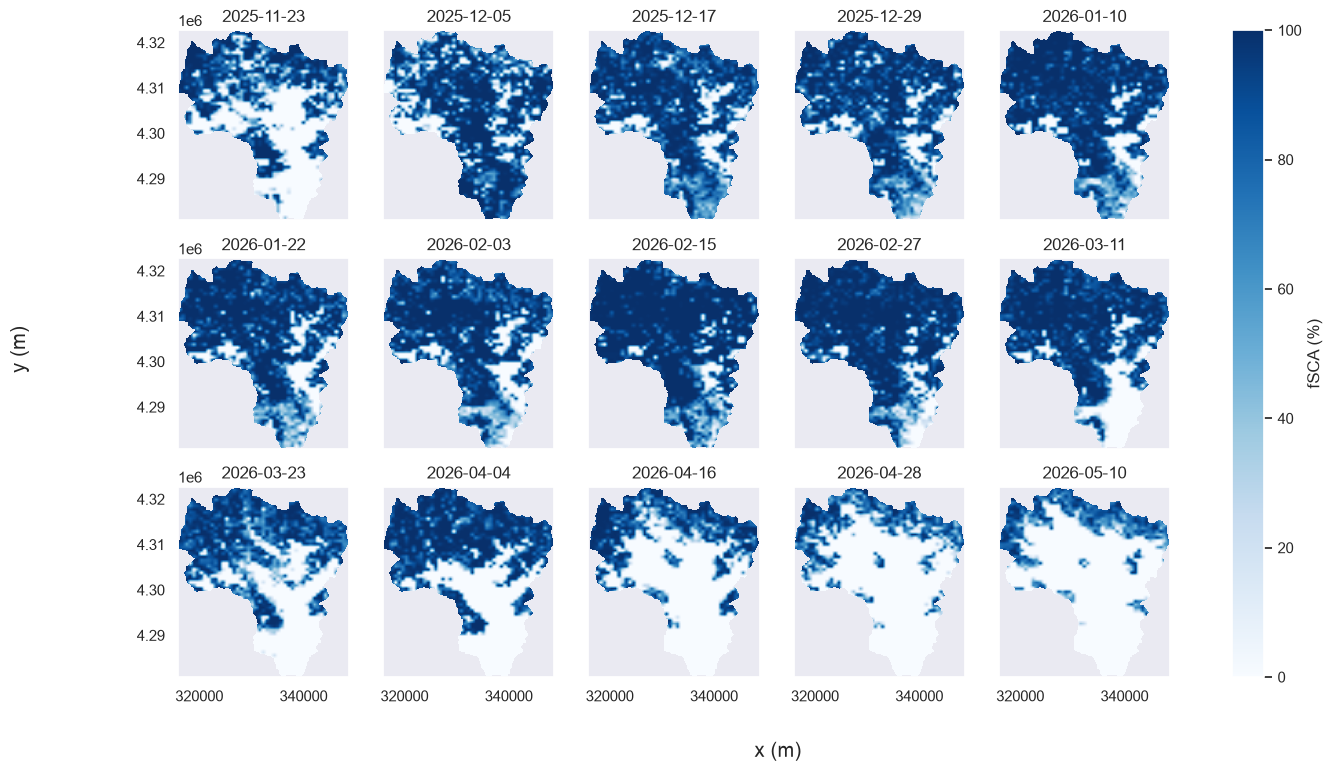

In [14]:
dates = pd.DatetimeIndex(np.concatenate([starts, ends])).normalize().unique().sort_values()
ncols = 5
nrows = int(np.ceil(len(dates) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), dates):
    im = fsca.sel(time=t).plot(ax=ax, cmap='Blues', vmin=0, vmax=100, add_colorbar=False)
    ax.set_title(str(t.date()))
    ax.set_xlabel('')
    ax.set_ylabel('')
for ax in axes.ravel()[len(dates):]:
    ax.set_visible(False)
fig.colorbar(im, ax=axes, label='fSCA (%)')
fig.supxlabel('x (m)')
fig.supylabel('y (m)')
plt.show()

Classify fSCA into snow cover categories. Default: 0 = no snow (<20%), 1 = patchy (20-70%), 2 = snow (≥70%); pass `bins` and `labels` to change.

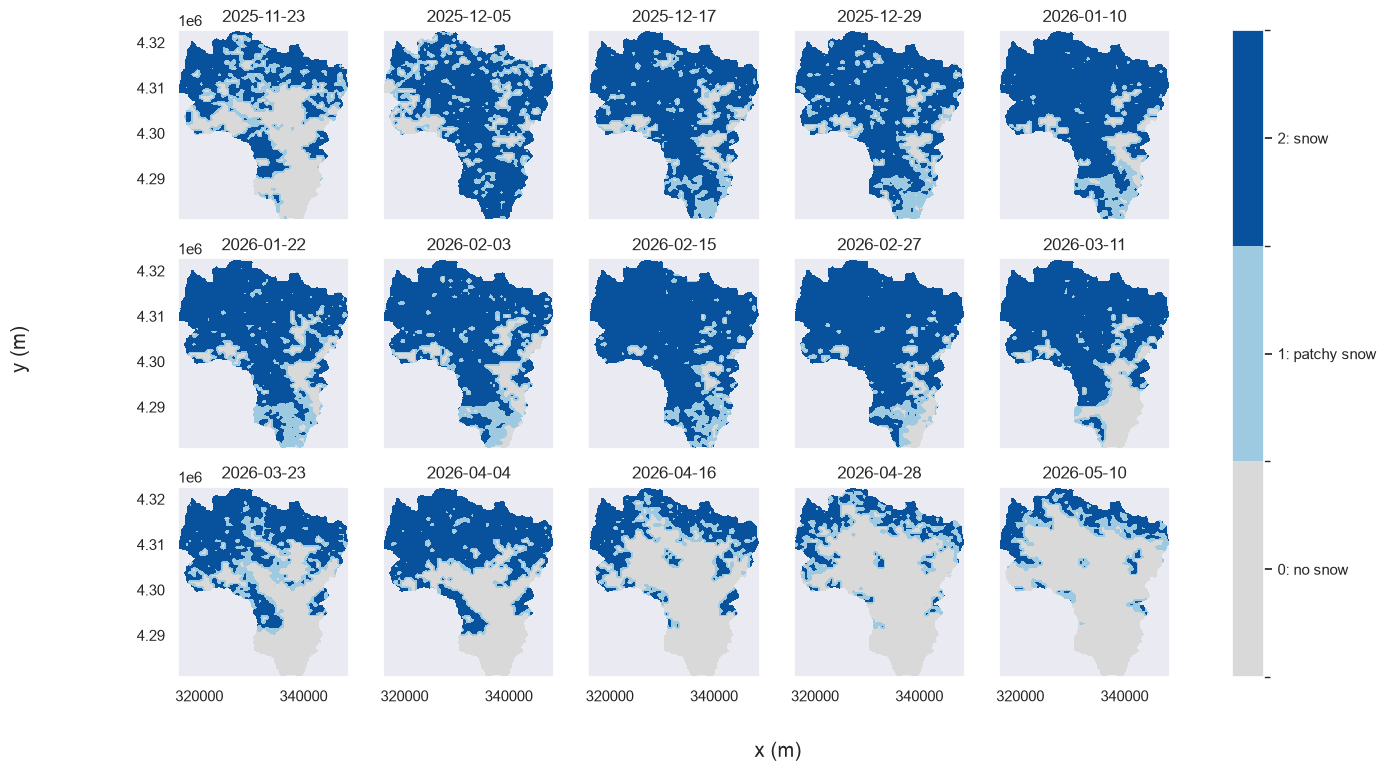

In [15]:
snow_class = classify_fsca(fsca)
labels = snow_class.attrs['class_labels']
cat_cmap = ListedColormap(['#d9d9d9', '#9ecae1', '#08519c'])
cat_norm = BoundaryNorm(np.arange(-0.5, len(labels)), cat_cmap.N)

fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), dates):
    im = snow_class.sel(time=t).where(snow_class.sel(time=t) >= 0).plot(ax=ax, cmap=cat_cmap, norm=cat_norm, add_colorbar=False)
    ax.set_title(str(t.date()))
    ax.set_xlabel('')
    ax.set_ylabel('')
for ax in axes.ravel()[len(dates):]:
    ax.set_visible(False)
cb = fig.colorbar(im, ax=axes, ticks=range(len(labels)))
cb.set_ticklabels([f'{i}: {l}' for i, l in enumerate(labels)])
fig.supxlabel('x (m)')
fig.supylabel('y (m)')
plt.show()

Categorical change for each NISAR pair. Stable classes keep their code (0 = no snow both days); increases and decreases are coded by how many classes changed.

In [16]:
snow_change = classify_change(snow_class, starts, ends, pair=nisar_80m['pair'].values)
change_names = snow_change.attrs['change_labels']
change_cmap = ListedColormap(['#d9d9d9', '#9ecae1', '#08519c', '#a1d99b', '#238b45', '#fdae6b', '#d94801'])
change_norm = BoundaryNorm(np.arange(-0.5, len(change_names)), change_cmap.N)
snow_change.sizes

Frozen({'pair': 14, 'y': 524, 'x': 410})

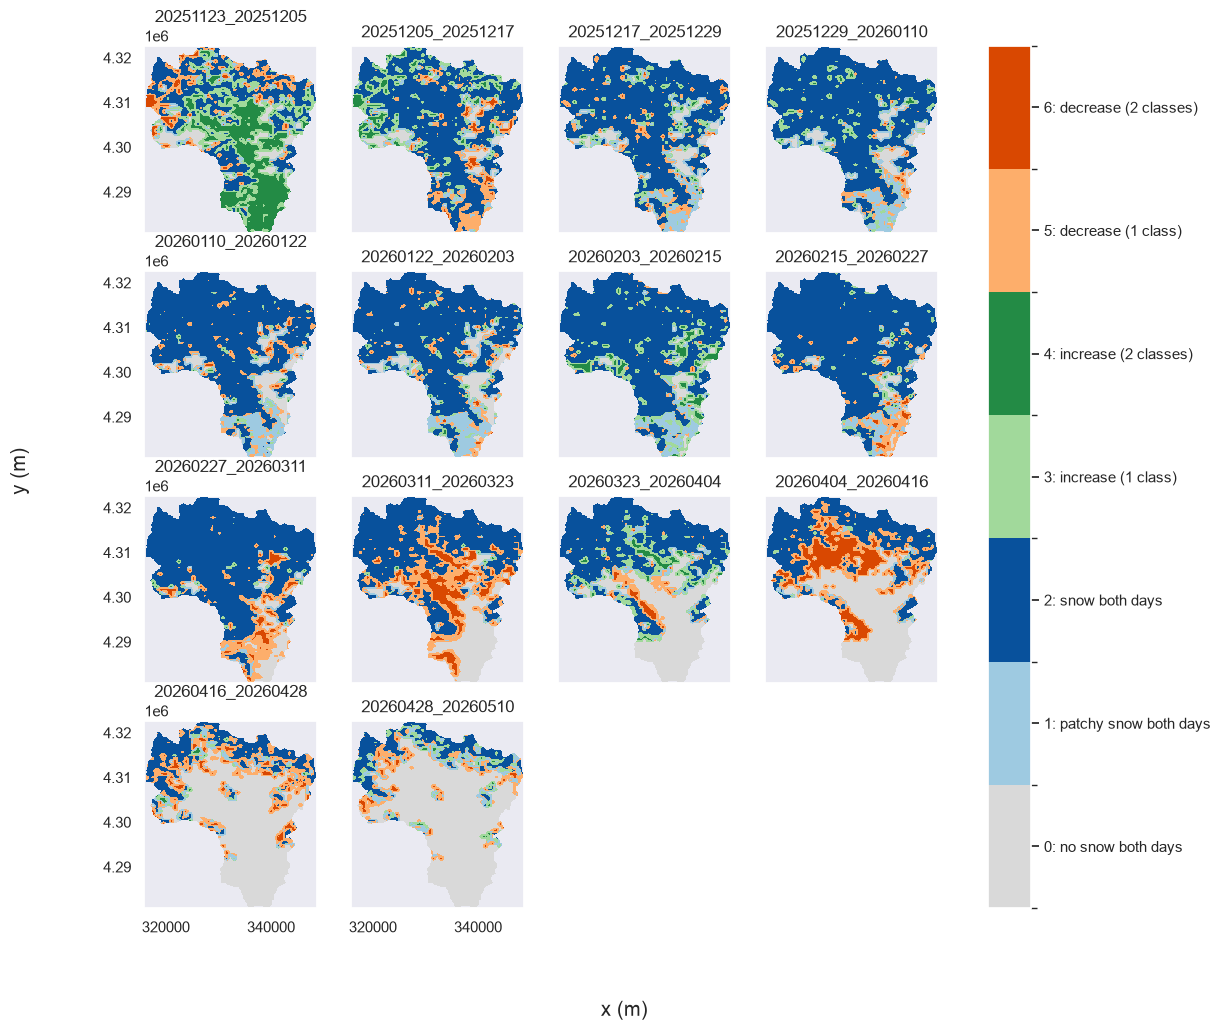

In [17]:
pairs = snow_change['pair'].values
ncols = 4
nrows = int(np.ceil(len(pairs) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows), sharex=True, sharey=True)
for ax, pair in zip(axes.ravel(), pairs):
    sc = snow_change.sel(pair=pair)
    im = sc.where(sc >= 0).plot(ax=ax, cmap=change_cmap, norm=change_norm, add_colorbar=False)
    ax.set_title(pair)
    ax.set_xlabel('')
    ax.set_ylabel('')
for ax in axes.ravel()[len(pairs):]:
    ax.set_visible(False)
cb = fig.colorbar(im, ax=axes, ticks=list(change_names))
cb.set_ticklabels([f'{i}: {l}' for i, l in change_names.items()])
fig.supxlabel('x (m)')
fig.supylabel('y (m)')
plt.show()